# NB2 · Label model — from rule votes to probabilistic labels

Input: `results/catalogue_v1/{items,votes}.csv` (rule engine v1). Output: `results/labels_v1/` (q per item, rule parameters, diagnostics, labelled episodes).

**Model.** Dawid–Skene (guide eq. 10–12) in numpy (`src/label_model.py`), with the changes the real votes forced. Each is documented in `docs/decisions.md`:

| # | Change | Why |
|---|---|---|
| D28 | Abstention is an observed output | Every v1 rule emits one label. Under the guide's likelihood (fired rules only), P(vote = l \| y, fired) = 1 for every class, so votes carry no information |
| D29 | Feasible classes per item from kind and hierarchy level | The typology defines each type at one level (multi-city dead → A1/G1; one zone → A1/G3/G4; …) |
| D30 | Applicability domains | Hold vs interpolation, and repeated vs missing hour, are mutually exclusive sub-signatures. Without domains they read as contradictions |
| D31 | R9 speaks for {G3, G4}; 'G' speaks for every G type | R10 and R11 refine R9 |
| D32 | Constrained one-coin parameters (a = propensity, b = false-positive rate) | The unconstrained model is not identifiable on these sparse, single-label votes |
| D33 | Defining rules get propensity prior (9, 1) | A class whose only evidence is one rule cannot otherwise be held (G4, G5) |
| D34 | Dirichlet(1) prior on class priors π | Prevents empty-class fixed points (vote-less fill items, singleton G5) |

**Baselines:** majority vote (plurality over feasible classes) and the guide's unconstrained Dawid–Skene (`structure="full"`, same feasibility and applicability).

**What this notebook can and cannot show.** There is no ground truth on real data. Here we show stability, parameter recovery on data drawn from the fitted model, robustness to rule families and priors, and agreement with the rules. Accuracy against known types comes from the injection benchmark (NB4).

In [1]:
import sys, subprocess
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/grid-event-or-data-artefact")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import rules_v1 as R1, label_model as LM, viz
from label_model import DawidSkene, CLASSES, majority_vote, entropy, ece, feasible_classes
from viz import LABEL_COL, savefig
LABEL_COL = {**LABEL_COL, "N": "#9AA0A6"}

CAT = ROOT / "results" / "catalogue_v1"
OUT = ROOT / "results" / "labels_v1"; OUT.mkdir(parents=True, exist_ok=True)
FIG = ROOT / "results" / "figures"
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)

items = pd.read_csv(CAT / "items.csv", parse_dates=["start", "end"])
votes = pd.read_csv(CAT / "votes.csv").set_index("item_id")
assert (votes.index == items.item_id).all()
print(items.kind.value_counts().to_dict(), "| rules:", list(votes.columns))

{'fill': 155, 'dead': 126, 'clock': 33, 'transfer': 13} | rules: ['R1', 'R2', 'R3', 'R4', 'R5', 'R6', 'R7', 'R8', 'R9', 'R10', 'R11', 'R12', 'R13', 'R14', 'R15', 'R16', 'R19', 'R20', 'R21']


## Fit: constrained Dawid–Skene (ours), unconstrained Dawid–Skene (guide), majority vote

In [2]:
ds = DawidSkene(structure="constrained").fit(votes, items, R1.RULE_KIND)
full = DawidSkene(structure="full").fit(votes, items, R1.RULE_KIND)
mv = majority_vote(votes, items)

lab = ds.q_.idxmax(axis=1); conf = ds.q_.max(axis=1)
lab_full = full.q_.idxmax(axis=1)
print("constrained: penalised loglik", round(ds.restarts_.penalised.max(), 2), "| restart agreement min", ds.restarts_.agree_with_best.min())
print("full       : loglik", round(full.loglik_, 2), "| restart agreement min", full.restarts_.agree_with_best.min())
stab = pd.DataFrame({"constrained": ds.restarts_.agree_with_best.describe(), "full (guide)": full.restarts_.agree_with_best.describe()}).T
stab.to_csv(OUT / "restart_stability.csv"); ds.restarts_.to_csv(OUT / "restarts_constrained.csv", index=False)
stab.round(3)

constrained: penalised loglik -610.85 | restart agreement min 1.0
full       : loglik -490.41 | restart agreement min 0.6269


,count,mean,std,min,25%,50%,75%,max
constrained,20.0,1.000,0.00,1.000,1.000,1.0,1.0,1.0
full (guide),20.0,0.832,0.19,0.627,0.627,1.0,1.0,1.0


### Learned class priors π (per item kind) and rule parameters

In [3]:
pi = ds.pi_.loc[:, (ds.pi_ > 0.0005).any()].round(3)
pi.to_csv(OUT / "class_priors.csv")
params = ds.params_table().merge(ds.rule_precision(votes), on="rule")
params["log_odds_a_over_b"] = np.log(params.a_propensity / params.b_false_positive).round(2)
params["defining"] = params.rule.isin(LM.DEFINING_RULES)
params["family"] = params.rule.map(R1.RULE_FAMILY)
params.to_csv(OUT / "rule_params.csv", index=False)
display(pi) if "display" in dir() else print(pi)
params

            A1     A2     A3     A4     G1     G2     G3     G4     G5      N
clock     0.00  0.000  0.000  0.392  0.000  0.000  0.000  0.000  0.000  0.608
dead      0.03  0.000  0.000  0.000  0.008  0.015  0.369  0.577  0.000  0.000
fill      0.00  0.366  0.607  0.000  0.000  0.000  0.000  0.000  0.000  0.027
transfer  0.00  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.125  0.875


,rule,output,speaks_for,n_applicable,a_propensity,b_false_positive,n_fired,learned_precision,log_odds_a_over_b,defining,family
0,R1,A1,A1,126,0.4034,0.0075,1,1.000,3.99,False,simultaneity
1,R2,A2,A2,70,0.6360,0.0193,12,0.991,3.50,True,hold
2,R3,A1,A1,126,0.6045,0.0151,3,0.666,3.69,False,hold
3,R4,A1,A1,126,0.4035,0.0225,3,0.333,2.89,False,hold
4,R5,G,G1+G2+G3+G4+G5,126,0.1684,0.1497,21,0.955,0.12,False,restoration
5,R6,G,G1+G2+G3+G4+G5,126,0.6797,0.0775,84,1.000,2.17,False,restoration
6,R8,G2,G2,126,0.9090,0.0075,1,0.994,4.80,True,city
7,R9,G3,G3+G4,126,0.9919,0.0733,122,1.000,2.61,False,single_zone
8,R10,G4,G4,126,0.8925,0.0563,69,0.964,2.76,True,calendar
9,R11,G3,G3,126,0.0996,0.0122,4,0.978,2.10,False,single_zone


## E12 — What the label model learned about each rule
For each rule: propensity *a* = P(fires | a class it speaks for) and false-positive rate *b* = P(fires | another feasible class).
log(a/b) is the evidence a vote carries.

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures/E12_label_model_rules.png


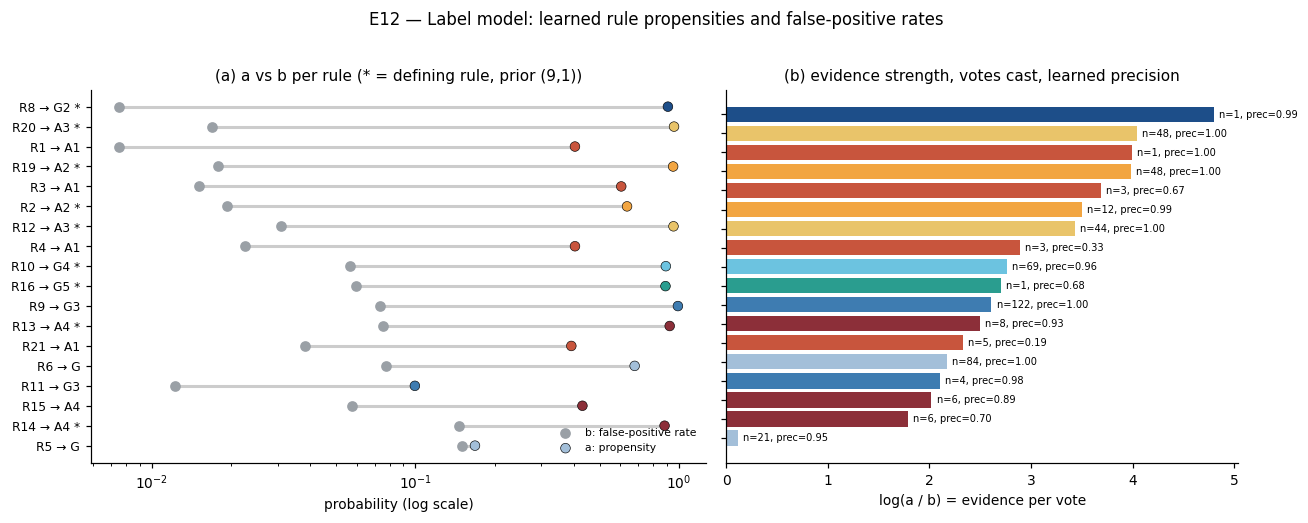

In [4]:
p = params.sort_values("log_odds_a_over_b")
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw=dict(width_ratios=[1.2, 1]))
y = np.arange(len(p))
axs[0].hlines(y, p.b_false_positive, p.a_propensity, color="#ccc", lw=2)
axs[0].scatter(p.b_false_positive, y, color="#9AA0A6", label="b: false-positive rate", zorder=3)
axs[0].scatter(p.a_propensity, y, c=[LABEL_COL.get(o if o != "G" else "G", "#999") for o in p.output], edgecolor="k", lw=.4, label="a: propensity", zorder=3, s=40)
axs[0].set_yticks(y); axs[0].set_yticklabels([f"{r} → {o}{' *' if d else ''}" for r, o, d in zip(p.rule, p.output, p.defining)], fontsize=8)
axs[0].set_xscale("log"); axs[0].set_xlabel("probability (log scale)"); axs[0].legend(fontsize=7, loc="lower right")
axs[0].set_title("(a) a vs b per rule (* = defining rule, prior (9,1))")
axs[1].barh(y, p.log_odds_a_over_b, color=[LABEL_COL.get(o, "#999") for o in p.output])
for yy, (n, pr) in enumerate(zip(p.n_fired, p.learned_precision)):
    axs[1].text(p.log_odds_a_over_b.iloc[yy] + .05, yy, f"n={n}, prec={pr:.2f}" if n else "never fires", va="center", fontsize=6.5)
axs[1].set_yticks(y); axs[1].set_yticklabels([])
axs[1].set_xlabel("log(a / b) = evidence per vote"); axs[1].set_title("(b) evidence strength, votes cast, learned precision")
fig.suptitle("E12 — Label model: learned rule propensities and false-positive rates", y=1.02)
fig.tight_layout(); savefig(fig, FIG, "E12_label_model_rules"); plt.show()

## Labels: counts, confidence, agreement with the baselines

In [5]:
print(pd.crosstab(lab.rename("label"), items.kind.values, margins=True).to_string())
print("\nconstrained DS vs majority vote (rows = MV):")
print(pd.crosstab(mv.rename("MV"), lab.rename("DS")).to_string())
print("\nconstrained DS vs unconstrained (guide) DS (rows = full):")
print(pd.crosstab(lab_full.rename("DS full"), lab.rename("DS")).to_string())
agree = pd.Series({"DS vs MV": (lab == mv).mean(), "DS vs DS-full": (lab == lab_full).mean(), "MV vs DS-full": (mv == lab_full).mean()}).round(3)
agree.to_csv(OUT / "labeler_agreement.csv"); agree

col_0  clock  dead  fill  transfer  All
label                                  
A1         0     3     0         0    3
A2         0     0    57         0   57
A3         0     0    95         0   95
A4        14     0     0         0   14
G2         0     1     0         0    1
G3         0    53     0         0   53
G4         0    69     0         0   69
G5         0     0     0         1    1
N         19     0     3        12   34
All       33   126   155        13  327

constrained DS vs majority vote (rows = MV):
DS  A1  A2  A3  A4  G2  G3  G4  G5   N
MV                                    
A1   3   0   0   0   0   2   0   0   0
A2   0  57   0   0   0   0   0   0   0
A3   0   0  92   0   0   0   0   0   0
A4   0   0   0  14   0   0   0   0   1
G2   0   0   0   0   1   0   0   0   0
G3   0   0   0   0   0  51   0   0   0
G4   0   0   0   0   0   0  69   0   0
G5   0   0   0   0   0   0   0   1   0
N    0   0   3   0   0   0   0   0  33

constrained DS vs unconstrained (guide) DS (

DS vs MV         0.982
DS vs DS-full    0.569
MV vs DS-full    0.575
dtype: float64

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures/E13_label_confidence.png


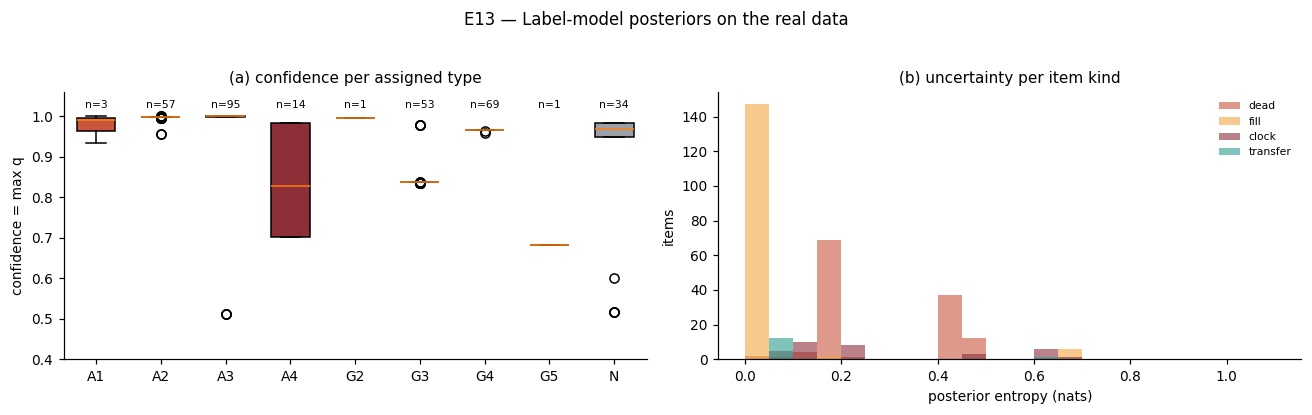

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
cls = [c for c in CLASSES if (lab == c).any()]
data_ = [conf[lab == c].values for c in cls]
bp = axs[0].boxplot(data_, labels=cls, patch_artist=True, widths=.6)
for patch, c in zip(bp["boxes"], cls): patch.set_facecolor(LABEL_COL.get(c, "#999"))
for i, c in enumerate(cls): axs[0].text(i + 1, 1.02, f"n={int((lab == c).sum())}", ha="center", fontsize=7)
axs[0].set_ylim(0.4, 1.06); axs[0].set_ylabel("confidence = max q"); axs[0].set_title("(a) confidence per assigned type")
H = entropy(ds.q_.values)
for k, col in zip(["dead", "fill", "clock", "transfer"], ["#C8553D", "#F2A541", "#8C2F39", "#2A9D8F"]):
    axs[1].hist(H[items.kind == k], bins=np.linspace(0, 1.1, 23), alpha=.6, color=col, label=k)
axs[1].set_xlabel("posterior entropy (nats)"); axs[1].set_ylabel("items"); axs[1].legend(fontsize=7); axs[1].set_title("(b) uncertainty per item kind")
fig.suptitle("E13 — Label-model posteriors on the real data", y=1.03)
fig.tight_layout(); savefig(fig, FIG, "E13_label_confidence"); plt.show()

## E14 — Key events: full posterior q(y)
Items that make up the guide's key events (C01–C12), plus the G2 candidate and the clock and transfer items with votes.

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures/E14_key_event_posteriors.png


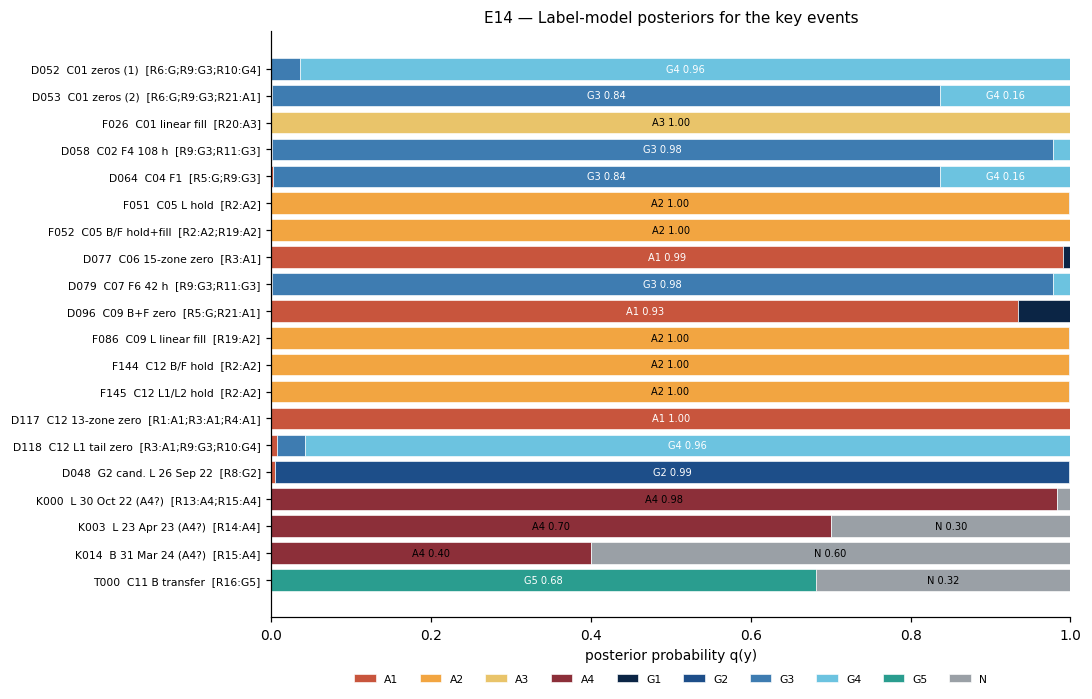

In [7]:
key_items = {"D052": "C01 zeros (1)", "D053": "C01 zeros (2)", "F026": "C01 linear fill", "D058": "C02 F4 108 h",
             "D064": "C04 F1", "F051": "C05 L hold", "F052": "C05 B/F hold+fill", "D077": "C06 15-zone zero",
             "D079": "C07 F6 42 h", "D096": "C09 B+F zero", "F086": "C09 L linear fill", "F144": "C12 B/F hold",
             "F145": "C12 L1/L2 hold", "D117": "C12 13-zone zero", "D118": "C12 L1 tail zero", "D048": "G2 cand. L 26 Sep 22",
             "K000": "L 30 Oct 22 (A4?)", "K003": "L 23 Apr 23 (A4?)", "K014": "B 31 Mar 24 (A4?)", "T000": "C11 B transfer"}
Q = ds.q_.loc[list(key_items)]
fig, ax = plt.subplots(figsize=(10, 6.4))
left = np.zeros(len(Q))
for c in CLASSES:
    if Q[c].sum() < 1e-3: continue
    ax.barh(range(len(Q)), Q[c], left=left, color=LABEL_COL.get(c, "#999"), label=c, edgecolor="white", lw=.4)
    for i, v in enumerate(Q[c]):
        if v > .12: ax.text(left[i] + v / 2, i, f"{c} {v:.2f}", ha="center", va="center", fontsize=6.5, color="white" if c[0] == "G" or c == "A1" else "black")
    left += Q[c].values
ax.set_yticks(range(len(Q))); ax.set_yticklabels([f"{k}  {v}  [{items.set_index('item_id').votes.get(k) if isinstance(items.set_index('item_id').votes.get(k), str) else 'no votes'}]" for k, v in key_items.items()], fontsize=7)
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel("posterior probability q(y)")
ax.legend(ncol=10, fontsize=7, loc="upper center", bbox_to_anchor=(.5, -.08))
ax.set_title("E14 — Label-model posteriors for the key events")
fig.tight_layout(); savefig(fig, FIG, "E14_key_event_posteriors"); plt.show()

## Parameter recovery (synthetic votes drawn from the fitted model)
For 20 seeds: draw true types and votes for the same 327 items (same feasible sets and applicability) from the fitted model, refit from scratch, and score against the drawn truth.
This checks identifiability and calibration **under the model's own assumptions**. It does not test the rules. That is NB4.

In [8]:
def macro_f1(y, p):
    f = []
    for c in sorted(set(y)):
        tp = sum((a == c) and (b == c) for a, b in zip(y, p)); fp = sum((a != c) and (b == c) for a, b in zip(y, p)); fn = sum((a == c) and (b != c) for a, b in zip(y, p))
        f.append(2 * tp / (2 * tp + fp + fn) if tp else 0.0)
    return float(np.mean(f))

rec = []
for s in range(20):
    rng = np.random.default_rng(100 + s)
    v_syn, y_true = ds.sample(items, rng)
    v_syn.index = votes.index
    for name, model in [("DS constrained", DawidSkene(n_restarts=5, seed=s)), ("DS full (guide)", DawidSkene(structure="full", n_restarts=5, seed=s))]:
        m = model.fit(v_syn, items, R1.RULE_KIND)
        pred = m.q_.idxmax(axis=1).values; cf = m.q_.max(axis=1).values
        onehot = np.array([[1.0 if c == t else 0.0 for c in CLASSES] for t in y_true])
        rec.append(dict(seed=s, labeler=name, accuracy=np.mean(pred == np.array(y_true)), macro_f1=macro_f1(y_true, pred),
                        ece=ece(cf, pred == np.array(y_true)), brier=float(((m.q_.values - onehot) ** 2).sum(axis=1).mean())))
    p_mv = majority_vote(v_syn, items).values
    rec.append(dict(seed=s, labeler="majority vote", accuracy=np.mean(p_mv == np.array(y_true)), macro_f1=macro_f1(y_true, p_mv), ece=np.nan, brier=np.nan))
rec = pd.DataFrame(rec)
rec.to_csv(OUT / "recovery_runs.csv", index=False)
recovery = rec.groupby("labeler")[["accuracy", "macro_f1", "ece", "brier"]].agg(["mean", "std"]).round(3)
recovery.to_csv(OUT / "recovery_summary.csv"); recovery

accuracy        macro_f1           ece         brier       
                    mean    std     mean    std   mean    std   mean    std
labeler                                                                    
DS constrained     0.922  0.021    0.872  0.080  0.033  0.012  0.124  0.028
DS full (guide)    0.682  0.058    0.493  0.077  0.276  0.065  0.577  0.118
majority vote      0.911  0.017    0.843  0.064    NaN    NaN    NaN    NaN

## Robustness on the real data: how many labels change?
(a) Drop one rule family at a time (guide ablation 2, plus the new interpolation family).
(b) Change one prior at a time: the false-positive prior b, the defining-rule prior, the Dirichlet prior on π.

In [9]:
def relabel_rate(model, cols):
    m = model.fit(votes[cols], items, R1.RULE_KIND)
    new = m.q_.idxmax(axis=1)
    return float((new != lab).mean()), {k: float((new[items.kind.values == k] != lab[items.kind.values == k]).mean()) for k in ["dead", "fill", "clock", "transfer"]}

rows = []
for fam in sorted(set(R1.RULE_FAMILY.values())):
    cols = [r for r in votes.columns if R1.RULE_FAMILY[r] != fam]
    tot, per = relabel_rate(DawidSkene(n_restarts=5), cols)
    rows.append(dict(test="drop family", setting=fam, rules_removed=",".join(r for r in votes.columns if R1.RULE_FAMILY[r] == fam), changed=tot, **{f"changed_{k}": v for k, v in per.items()}))
for name, kw in [("prior_b=(1,4)", dict(prior_b=(1, 4))), ("prior_b=(1,19)", dict(prior_b=(1, 19))), ("no defining prior", dict(use_defining=False)),
                 ("prior_pi=0.5", dict(prior_pi=0.5)), ("prior_pi=2", dict(prior_pi=2)), ("init a=0.9,b=0.02", dict(init_fire=.9, init_other=.02))]:
    tot, per = relabel_rate(DawidSkene(n_restarts=5, **kw), list(votes.columns))
    rows.append(dict(test="prior / init", setting=name, rules_removed="", changed=tot, **{f"changed_{k}": v for k, v in per.items()}))
robust = pd.DataFrame(rows).round(3)
robust.to_csv(OUT / "robustness.csv", index=False)
robust

,test,setting,rules_removed,changed,changed_dead,changed_fill,changed_clock,changed_transfer
0,drop family,calendar,"R10,R14",0.171,0.389,0.000,0.212,0.000
1,drop family,city,R8,0.003,0.008,0.000,0.000,0.000
2,drop family,clock,"R13,R15",0.024,0.000,0.000,0.242,0.000
3,drop family,conservation,R16,0.037,0.000,0.000,0.000,0.923
4,drop family,hold,"R2,R3,R4,R12",0.006,0.000,0.013,0.000,0.000
5,drop family,interpolation,"R19,R20,R21",0.468,0.008,0.981,0.000,0.000
6,drop family,restoration,"R5,R6",0.000,0.000,0.000,0.000,0.000
7,drop family,simultaneity,"R1,R7",0.000,0.000,0.000,0.000,0.000
8,drop family,single_zone,"R9,R11",0.000,0.000,0.000,0.000,0.000
9,prior / init,"prior_b=(1,4)",,0.018,0.000,0.000,0.182,0.000


saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures/E15_label_robustness.png


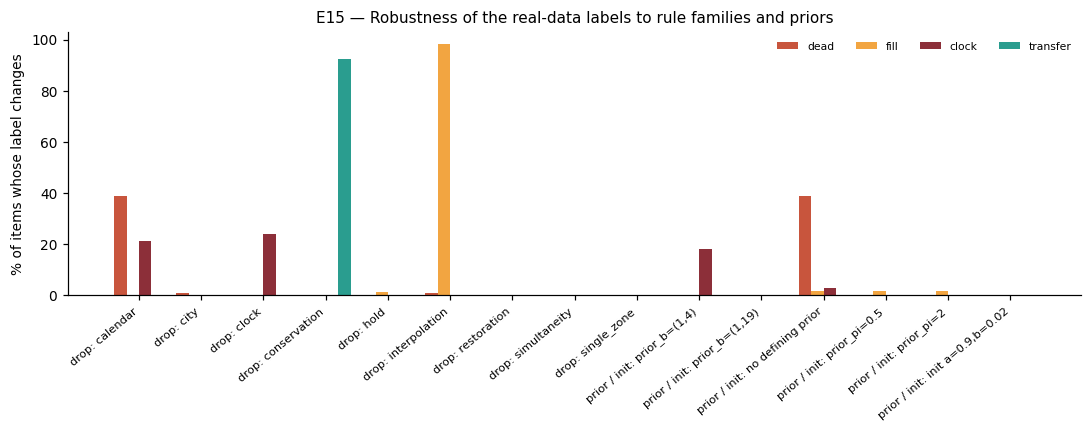

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
r = robust.copy(); r["name"] = r.test.str.replace("drop family", "drop") + ": " + r.setting
x = np.arange(len(r)); w = .2
for i, (k, col) in enumerate(zip(["dead", "fill", "clock", "transfer"], ["#C8553D", "#F2A541", "#8C2F39", "#2A9D8F"])):
    ax.bar(x + (i - 1.5) * w, 100 * r[f"changed_{k}"], w, color=col, label=k)
ax.set_xticks(x); ax.set_xticklabels(r.name, rotation=40, ha="right", fontsize=7.5)
ax.set_ylabel("% of items whose label changes"); ax.legend(fontsize=7, ncol=4)
ax.set_title("E15 — Robustness of the real-data labels to rule families and priors")
fig.tight_layout(); savefig(fig, FIG, "E15_label_robustness"); plt.show()

## Labelled catalogue: items and episodes
`q.csv` holds one row per item with the full posterior. `episodes_labelled.csv` lists compound episodes as a sequence of item labels, for example `A2 → A1` for C12.

In [11]:
q = items[["item_id", "kind", "episode", "system", "start", "end", "duration_h", "cities", "zones", "n_cities", "n_zones", "votes", "mv_label"]].copy()
q = q.rename(columns={"mv_label": "inspection_label_v1"})
q["feasible"] = [",".join(feasible_classes(it)) for it in items.itertuples()]
for c in CLASSES: q[f"q_{c}"] = ds.q_[c].values.round(4)
q["label"] = lab.values; q["confidence"] = conf.values.round(4); q["entropy"] = entropy(ds.q_.values).round(4)
q["label_majority_vote"] = mv.values; q["label_ds_full"] = lab_full.values
q["family"] = np.where(q.label.str.startswith("A"), "artefact", np.where(q.label.str.startswith("G"), "grid event", "normal"))
q.to_csv(OUT / "q.csv", index=False)

ep = q[q.episode.notna()].sort_values("start").groupby("episode")
episodes = pd.DataFrame({
    "start": ep.start.min(), "end": ep.end.max(), "n_items": ep.size(),
    "cities": ep.cities.agg(lambda c: "+".join(sorted(set("+".join(c).split("+"))))),
    "n_zones_max": ep.n_zones.max(),
    "sequence": ep[["label", "confidence"]].apply(lambda g: " → ".join(f"{l}({c:.2f})" for l, c in zip(g.label, g.confidence))),
    "items": ep.item_id.agg(",".join),
    "families": ep.family.agg(lambda f: "+".join(sorted(set(f)))),
})
episodes["duration_h"] = ((episodes.end - episodes.start).dt.total_seconds() / 3600).round(1)
episodes.to_csv(OUT / "episodes_labelled.csv")
big = episodes[(episodes.n_items >= 2) | (episodes.n_zones_max >= 2)].sort_values("start")
print(len(episodes), "episodes;", len(big), "with >= 2 items or >= 2 zones")
big[["start", "duration_h", "cities", "n_zones_max", "sequence", "families"]]

230 episodes; 79 with >= 2 items or >= 2 zones


,start,duration_h,cities,n_zones_max,sequence,families
episode,,,,,,
EP002,2022-09-25 08:20:00,1.0,Laayoune,2,A2(1.00),artefact
EP003,2022-09-26 08:20:00,0.8,Laayoune,5,G2(0.99),grid event
EP005,2022-09-29 09:20:00,1.8,Boujdour,3,A2(1.00),artefact
EP007,2022-10-01 09:00:00,2.7,Foum eloued,1,G4(0.96) → A3(1.00),artefact+grid event
EP013,2022-10-12 08:30:00,1.0,Laayoune,4,A2(1.00),artefact
...,...,...,...,...,...,...
EP215,2024-03-31 09:10:00,45.8,Boujdour+Foum eloued+Laayoune,13,A2(1.00) → A1(1.00) → A2(1.00) → G4(0.96),artefact+grid event
EP216,2024-04-06 08:20:00,2.0,Laayoune,4,G4(0.96) → A2(1.00) → N(0.52),artefact+grid event+normal
EP220,2024-04-21 02:00:00,1.0,Laayoune,5,A2(1.00),artefact


## Summary numbers (copied into docs/results_summary.md)

In [12]:
summary = {
    "items": len(items), "labels": lab.value_counts().to_dict(),
    "artefact_items": int(q.family.eq("artefact").sum()), "grid_items": int(q.family.eq("grid event").sum()), "normal_items": int(q.family.eq("normal").sum()),
    "mean_confidence": round(float(conf.mean()), 3), "items_conf_below_0.7": int((conf < .7).sum()),
    "restart_agreement_min_constrained": float(ds.restarts_.agree_with_best.min()), "restart_agreement_min_full": float(full.restarts_.agree_with_best.min()),
    "agreement_DS_MV": float(agree["DS vs MV"]), "agreement_DS_DSfull": float(agree["DS vs DS-full"]),
}
import json
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
summary

{'items': 327,
 'labels': {'A3': 95,
  'G4': 69,
  'A2': 57,
  'G3': 53,
  'N': 34,
  'A4': 14,
  'A1': 3,
  'G2': 1,
  'G5': 1},
 'artefact_items': 169,
 'grid_items': 124,
 'normal_items': 34,
 'mean_confidence': 0.945,
 'items_conf_below_0.7': 8,
 'restart_agreement_min_constrained': 1.0,
 'restart_agreement_min_full': 0.6269,
 'agreement_DS_MV': 0.982,
 'agreement_DS_DSfull': 0.569}